# Calculus with SciPy

In [2]:
import math
from typing import cast

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import quad, solve_ivp
from scipy.optimize import approx_fprime

## Task 1. User activity dynamics

### Analytical derivative

$$f(t)=1000\,t\,e^{-0.2t},\qquad u(t)=1000t,\quad v(t)=e^{-0.2t}$$

$$u'(t)=1000,\qquad v'(t)=-0.2\,e^{-0.2t}$$

$$f'(t)=u'v+uv'=1000\,e^{-0.2t}+1000t\cdot(-0.2)\,e^{-0.2t}=1000\,e^{-0.2t}\,(1-0.2t)$$

### Peak load

$$f'(t^*)=0\ \Rightarrow\ 1000\,e^{-0.2t^*}(1-0.2t^*)=0$$

Since $e^{-0.2t}>0$ for all $t$: $\ 1-0.2t^*=0\ \Rightarrow\ t^*=5$.

For $t<5$ we have $f'(t)>0$, for $t>5$ we have $f'(t)<0$, so $t^*=5$ is a maximum:

$$f(5)=5000\,e^{-1}\approx1839\ \text{sessions},\qquad 8{:}00+5\ \text{h}=13{:}00$$

**Analytical values of the derivative:**

$$f'(2)=1000\,e^{-0.4}\cdot0.6\approx402.19$$

$$f'(6)=1000\,e^{-1.2}\cdot(-0.2)\approx-60.24$$

$$f'(10)=1000\,e^{-2}\cdot(-1)\approx-135.34$$

In [4]:
DAY_START_HOUR = 8


def sessions(t: float) -> float:
  return 1000 * t * math.exp(-0.2 * t)


def sessions_derivative(t: float) -> float:
  return 1000 * math.exp(-0.2 * t) * (1 - 0.2 * t)


def to_clock(t: float) -> str:
  total_minutes = round((DAY_START_HOUR + t) * 60)

  return f'{total_minutes // 60:02d}:{total_minutes % 60:02d}'

In [5]:
t_peak = 1 / 0.2

print(f't* = {t_peak} -> {to_clock(t_peak)}')
print(f"f'(t*) = {sessions_derivative(t_peak):.4f}")
print(f'Peak load: f(t*) = {sessions(t_peak):.0f} sessions')

t* = 5.0 -> 13:00
f'(t*) = 0.0000
Peak load: f(t*) = 1839 sessions


### Numerical derivative

In [7]:
EPSILON = 1e-6
checkpoints = [2, 6, 10]

numerical_derivatives: dict[int, float] = {}
for t in checkpoints:
  gradient = cast(np.ndarray, approx_fprime(np.array([t], dtype=float), lambda x: sessions(x[0]), EPSILON))
  numerical_derivatives[t] = float(gradient[0])
  print(f"{to_clock(t)} (t = {t}): f'(t) ≈ {numerical_derivatives[t]:.4f}")

10:00 (t = 2): f'(t) ≈ 402.1919
14:00 (t = 6): f'(t) ≈ -60.2389
18:00 (t = 10): f'(t) ≈ -135.3353


### Numerical vs analytical

In [14]:
print(f"{'Time':<7}{'t':<4}{'Numerical':>12}{'Analytical':>12}{'Abs error':>12}")
for t in checkpoints:
  analytical = sessions_derivative(t)
  error = abs(numerical_derivatives[t] - analytical)
  print(f'{to_clock(t):<7}{t:<4}{numerical_derivatives[t]:>12.4f}{analytical:>12.4f}{error:>12.2e}')

Time   t      Numerical  Analytical   Abs error
10:00  2       402.1919    402.1920    1.07e-04
14:00  6       -60.2389    -60.2388    2.37e-05
18:00  10     -135.3353   -135.3353    7.22e-07


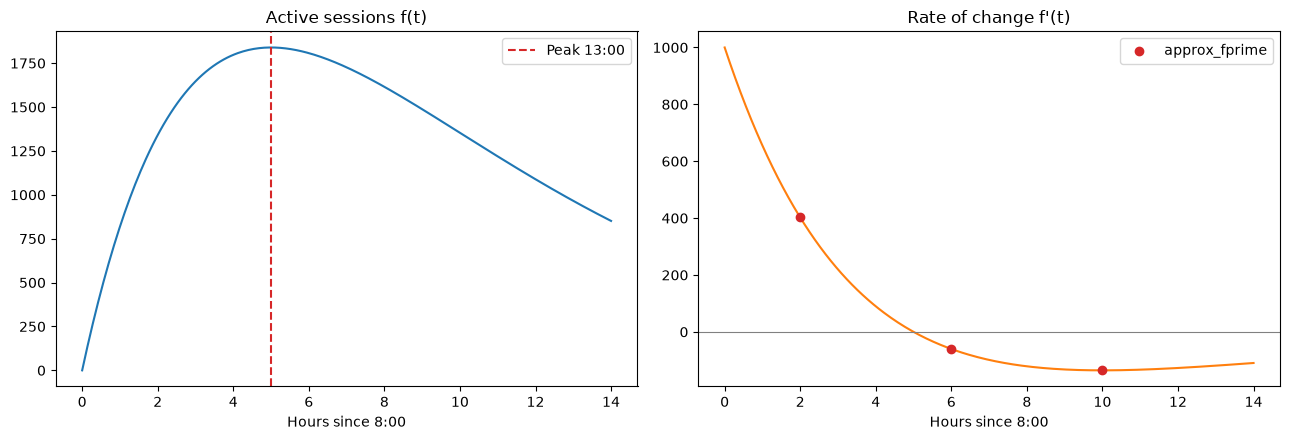

In [18]:
hours = np.linspace(0, 14, 300)

fig, (ax_sessions, ax_rate) = plt.subplots(1, 2, figsize=(13, 4.5))

ax_sessions.plot(hours, [sessions(t) for t in hours])
ax_sessions.axvline(t_peak, color='tab:red', linestyle='--', label=f'Peak {to_clock(t_peak)}')
ax_sessions.set_title('Active sessions f(t)')
ax_sessions.set_xlabel('Hours since 8:00')
ax_sessions.legend()

ax_rate.plot(hours, [sessions_derivative(t) for t in hours], color='tab:orange')
ax_rate.axhline(0, color='gray', linewidth=0.8)
ax_rate.scatter(checkpoints, [numerical_derivatives[t] for t in checkpoints], color='tab:red', zorder=3, label='approx_fprime')
ax_rate.set_title("Rate of change f'(t)")
ax_rate.set_xlabel('Hours since 8:00')
ax_rate.legend()

plt.tight_layout()
plt.show()

### Business interpretation

- Numerical and analytical derivatives differ by at most ~1e-4 (0.00003% of the value), so `approx_fprime` is accurate enough for this model.
- At 10:00 f'(2) ≈ +402 sessions/hour: load is still growing fast, so IT should be scaling servers up at this time.
- At 18:00 f'(10) ≈ -135 sessions/hour: load is falling, so servers can be gradually released.
- The maximum number of servers should be running around 13:00, when activity peaks at ~1839 sessions.

## Task 2. Learning process model

### Model

In [42]:
M = 100
r = 0.15
TARGET = 90


def learning_rate(t: float, K: np.ndarray) -> np.ndarray:
  return r * (M - K)

### Numerical solution

In [43]:
days = np.linspace(0, 30, 301)
solution = solve_ivp(learning_rate, (0, 30), [10], t_eval=days, rtol=1e-8, atol=1e-8)
exact = M - (M - 10) * np.exp(-r * days)

for day in range(0, 31, 5):
  print(f'Day {day:>2}: K = {solution.y[0][day * 10]:.2f}%')
print(f'\nMax deviation from exact solution: {np.max(np.abs(solution.y[0] - exact)):.2e}')

Day  0: K = 10.00%
Day  5: K = 57.49%
Day 10: K = 79.92%
Day 15: K = 90.51%
Day 20: K = 95.52%
Day 25: K = 97.88%
Day 30: K = 99.00%

Max deviation from exact solution: 1.84e-07


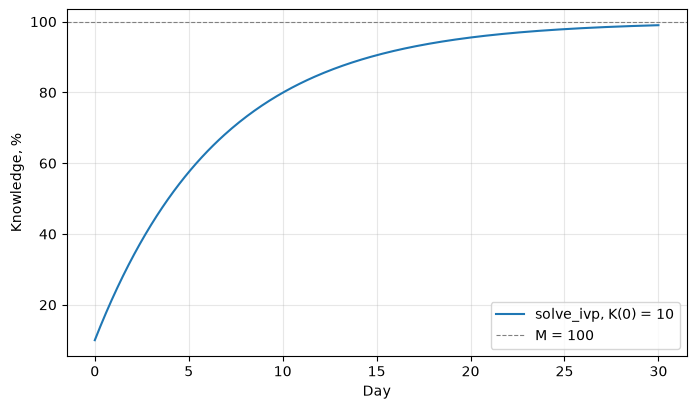

In [47]:
plt.figure(figsize=(8, 4.5))
plt.plot(solution.t, solution.y[0], label='solve_ivp, K(0) = 10')
plt.axhline(M, color='gray', linestyle='--', linewidth=0.8, label='M = 100')
plt.xlabel('Day')
plt.ylabel('Knowledge, %')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Initial level comparison

K(0) =  5%: reaches 90% on day 15.01 (analytical 15.01)
K(0) = 10%: reaches 90% on day 14.65 (analytical 14.65)
K(0) = 20%: reaches 90% on day 13.86 (analytical 13.86)


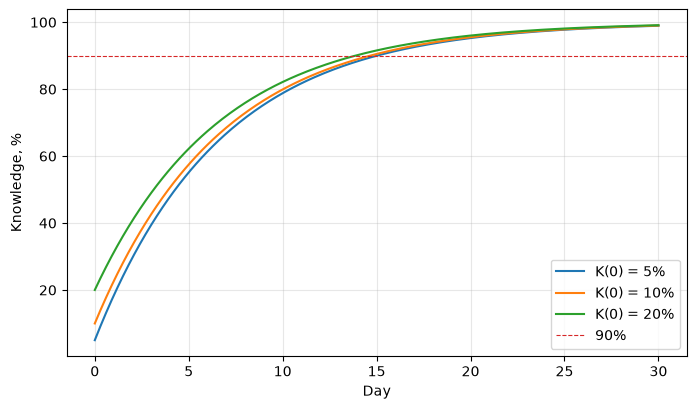

In [79]:
def reached_target(t: float, K: np.ndarray) -> float:
  return K[0] - TARGET


students: dict[int, float] = {}
plt.figure(figsize=(8, 4.5))

for initial_level in [5, 10, 20]:
  result = solve_ivp(learning_rate, (0, 30), [initial_level], events=reached_target, dense_output=True, rtol=1e-8, atol=1e-8)
  students[initial_level] = float(result.t_events[0][0])
  plt.plot(days, result.sol(days)[0], label=f'K(0) = {initial_level}%')

  analytical_time = math.log((M - initial_level) / (M - TARGET)) / r
  print(f'K(0) = {initial_level:>2}%: reaches {TARGET}% on day {students[initial_level]:.2f} (analytical {analytical_time:.2f})')

plt.axhline(TARGET, color='tab:red', linestyle='--', linewidth=0.8, label=f'{TARGET}%')
plt.xlabel('Day')
plt.ylabel('Knowledge, %')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [99]:
print(f'5% vs 20% start: {students[5] - students[20]:.2f} days difference')

5% vs 20% start: 1.15 days difference


### Conclusion

- A student starting at 10% reaches 90% in about 14.65 days; `solve_ivp` matches the exact solution K(t) = 100 - 90e^(-0.15t).
- Starting at 5% takes 15.01 days, starting at 20% takes 13.86 days.
- A 4× better start (20% vs 5%) saves only ~1.15 days: the gap to M shrinks exponentially, so initial preparation helps, but its effect is modest compared to the learning rate r.

## Task 3. Ad campaign efficiency

### Analytical integral

$$F(t)=\int500\,e^{-0.3t}\,dt=500\cdot\frac{1}{-0.3}e^{-0.3t}+C=-\frac{5000}{3}e^{-0.3t}+C$$

**First 7 days** (Newton–Leibniz):

$$\int_0^7500\,e^{-0.3t}\,dt=F(7)-F(0)=-\frac{5000}{3}e^{-2.1}+\frac{5000}{3}=\frac{5000}{3}\left(1-e^{-2.1}\right)\approx1666.67\cdot0.87754\approx1462.57$$

**Theoretical maximum:**

$$\int_0^\infty500\,e^{-0.3t}\,dt=\lim_{T\to\infty}\frac{5000}{3}\left(1-e^{-0.3T}\right)=\frac{5000}{3}\approx1666.67$$

**First week efficiency:**

$$\frac{1462.57}{1666.67}\cdot100\%=\left(1-e^{-2.1}\right)\cdot100\%\approx87.75\%$$

In [101]:
def registrations(t: float) -> float:
  return 500 * math.exp(-0.3 * t)


analytical_week = 5000 / 3 * (1 - math.exp(-2.1))
analytical_max = 5000 / 3

### Numerical check

In [103]:
numerical_week, week_error = quad(registrations, 0, 7)

print(f'Analytical: {analytical_week:.4f}')
print(f'quad:       {numerical_week:.4f} (error estimate {week_error:.1e})')
print(f'Match: {math.isclose(numerical_week, analytical_week)}')

Analytical: 1462.5726
quad:       1462.5726 (error estimate 1.6e-11)
Match: True


### Theoretical maximum

In [104]:
numerical_max, max_error = quad(registrations, 0, np.inf)

print(f'Analytical: {analytical_max:.4f}')
print(f'quad:       {numerical_max:.4f} (error estimate {max_error:.1e})')
print(f'Match: {math.isclose(numerical_max, analytical_max)}')

Analytical: 1666.6667
quad:       1666.6667 (error estimate 1.1e-08)
Match: True


### First week efficiency

In [105]:
week_share = numerical_week / numerical_max * 100

print(f'First 7 days: {numerical_week:.0f} of {numerical_max:.0f} registrations ({week_share:.2f}%)')

First 7 days: 1463 of 1667 registrations (87.75%)


### Conclusion

- The first week brings ~1463 registrations, and `quad` matches the Newton–Leibniz result.
- The theoretical maximum of the campaign is ~1667 registrations.
- 87.75% of all possible registrations happen in the first 7 days, so running the campaign longer than a week adds only ~12% more sign-ups.

## Task 4. Function of two variables

### Partial derivatives

$$f(x,y)=0.5x^2+0.3y^2+0.2xy+10x+5y$$

$$\frac{\partial f}{\partial x}=x+0.2y+10,\qquad \frac{\partial f}{\partial y}=0.6y+0.2x+5$$

**At the point $(10,20)$:**

$$\frac{\partial f}{\partial x}(10,20)=10+4+10=24,\qquad \frac{\partial f}{\partial y}(10,20)=12+2+5=19$$

**Linear approximation** with $\Delta x=0.5,\ \Delta y=-0.3$:

$$\Delta f\approx24\cdot0.5+19\cdot(-0.3)=12-5.7=6.3$$

**Exact change:**

$$f(10,20)=50+120+40+100+100=410$$

$$f(10.5,19.7)=55.125+116.427+41.37+105+98.5=416.422$$

$$\Delta f=416.422-410=6.422$$

In [107]:
def f(point: np.ndarray) -> float:
  x, y = point

  return 0.5 * x ** 2 + 0.3 * y ** 2 + 0.2 * x * y + 10 * x + 5 * y


def df_dx(x: float, y: float) -> float:
  return x + 0.2 * y + 10


def df_dy(x: float, y: float) -> float:
  return 0.6 * y + 0.2 * x + 5

### Numerical gradient

In [109]:
point = np.array([10.0, 20.0])
numerical_gradient = cast(np.ndarray, approx_fprime(point, f, 1e-6))

print(f'Numerical gradient at (10, 20): {numerical_gradient}')

Numerical gradient at (10, 20): [24.00000047 19.00000027]


### Numerical vs analytical

In [110]:
analytical_gradient = np.array([df_dx(10, 20), df_dy(10, 20)])

print(f'Analytical gradient: {analytical_gradient}')
print(f'Numerical gradient:  {numerical_gradient}')
print(f'Match: {np.allclose(numerical_gradient, analytical_gradient, atol=1e-4)}')

Analytical gradient: [24. 19.]
Numerical gradient:  [24.00000047 19.00000027]
Match: True


### Linear approximation

In [111]:
dx, dy = 0.5, -0.3

approximate_change = analytical_gradient[0] * dx + analytical_gradient[1] * dy
exact_change = f(point + np.array([dx, dy])) - f(point)

print(f'Approximate change: {approximate_change:.4f}')
print(f'Exact change:       {exact_change:.4f}')
print(f'Difference:         {exact_change - approximate_change:.4f} ({abs(exact_change - approximate_change) / exact_change * 100:.2f}%)')

Approximate change: 6.3000
Exact change:       6.4220
Difference:         0.1220 (1.90%)


### Conclusion

- The gradient at (10, 20) is (24, 19); `approx_fprime` reproduces it up to ~5e-7.
- The linear approximation gives Δf ≈ 6.3, the exact change is 6.422.
- The 0.122 gap (~1.9%) comes from the quadratic terms that the first-order approximation ignores: 0.5·Δx² + 0.3·Δy² + 0.2·Δx·Δy = 0.122.